# MetroGuard: Metro Compressor Anomaly Detection

This notebook builds and evaluates an anomaly detector using the UCI MetroPT-3 air-compressor sensor data.

The main model is **Isolation Forest**. A simple sensor-threshold baseline is included for comparison. The four incident periods reported by UCI are used to create an *assumed two-hour warning window* for evaluation. These are not verified labels for individual sensor readings, so the results should be described as anomaly detection against an experimental reference, not as proven failure prediction.


In [1]:
from pathlib import Path
import json
import shutil
import zipfile

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

pd.set_option("display.max_columns", 100)
RANDOM_STATE = 42
print("Libraries loaded")

Libraries loaded


## 1. Load the dataset

In [2]:
# Download the dataset from its UCI page
DATA_DIR = Path("/content/metroguard_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)
ZIP_PATH = DATA_DIR / "metropt3_dataset.zip"
CSV_PATH = DATA_DIR / "MetroPT3(AirCompressor).csv"
DATA_URL = "https://archive.ics.uci.edu/static/public/791/metropt+3+dataset.zip"

if not CSV_PATH.exists():
    print("Downloading MetroPT-3 from UCI...")
    with requests.get(DATA_URL, stream=True, timeout=(30, 180)) as response:
        response.raise_for_status()
        with open(ZIP_PATH, "wb") as file:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    file.write(chunk)

    with zipfile.ZipFile(ZIP_PATH) as archive:
        csv_name = next(
            (name for name in archive.namelist()
             if name.lower().endswith("metropt3(aircompressor).csv")),
            None,
        )
        if csv_name is None:
            raise FileNotFoundError("The MetroPT3(AirCompressor).csv file was not found in the downloaded ZIP.")
        with archive.open(csv_name) as source, open(CSV_PATH, "wb") as target:
            shutil.copyfileobj(source, target)

print("Reading CSV...")
df = pd.read_csv(CSV_PATH, low_memory=False)
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df = df.dropna(subset=["timestamp"]).sort_values("timestamp").reset_index(drop=True)

# The CSV may include an index column that is not a sensor measurement.
df = df.drop(columns=[c for c in df.columns if c.lower().startswith("unnamed:")], errors="ignore")

sensor_features = [
    "TP2", "TP3", "H1", "DV_pressure", "Reservoirs",
    "Oil_temperature", "Motor_current", "COMP", "DV_eletric",
    "Towers", "MPG", "LPS", "Pressure_switch", "Oil_level",
    "Caudal_impulses",
]
missing_columns = [c for c in sensor_features if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing expected sensor columns: {missing_columns}")

# Keep sensor columns numeric before calculating averages and rolling features.
df[sensor_features] = df[sensor_features].apply(pd.to_numeric, errors="coerce")
print(f"Rows: {len(df):,} | Columns: {len(df.columns)}")
print(f"Period: {df['timestamp'].min()} to {df['timestamp'].max()}")
print(f"Duplicate rows: {df.duplicated().sum():,}")
display(df[sensor_features].isna().sum().to_frame("Missing values"))

Reading CSV...
Rows: 1,516,948 | Columns: 16
Period: 2020-02-01 00:00:00 to 2020-09-01 03:59:50
Duplicate rows: 0


,Missing values
TP2,0
TP3,0
H1,0
DV_pressure,0
Reservoirs,0
Oil_temperature,0
Motor_current,0
COMP,0
DV_eletric,0
Towers,0


## 2. Quick look at the sensor data

Most common timestamp intervals (seconds):


,rows
seconds,
10.0,1337521
9.0,128277
12.0,38321
13.0,7988
11.0,4471
21.0,10


,min,50%,max
TP2,-0.032,-0.012,10.676
TP3,0.730,8.960,10.302
H1,-0.036,8.784,10.288
DV_pressure,-0.032,-0.020,9.844
Reservoirs,0.712,8.960,10.300
Oil_temperature,15.400,62.700,89.050
Motor_current,0.020,0.045,9.295
COMP,0.000,1.000,1.000
DV_eletric,0.000,0.000,1.000
Towers,0.000,1.000,1.000


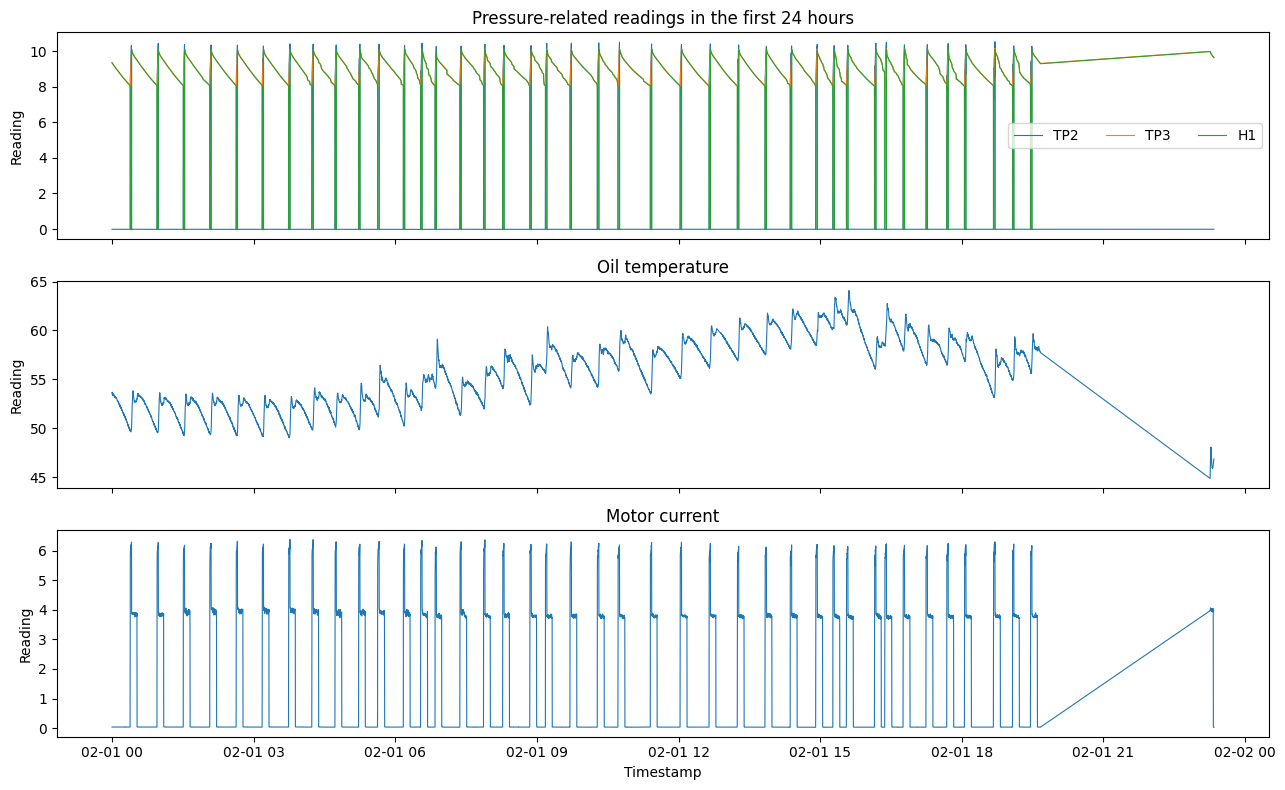

In [3]:
intervals = df["timestamp"].diff().dt.total_seconds().dropna()
print("Most common timestamp intervals (seconds):")
display(intervals.value_counts().head(6).rename_axis("seconds").to_frame("rows"))
display(df[sensor_features].describe().T[["min", "50%", "max"]].round(3))

first_day = df.loc[df["timestamp"] < df["timestamp"].min() + pd.Timedelta(days=1)]
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
for col in ["TP2", "TP3", "H1"]:
    axes[0].plot(first_day["timestamp"], first_day[col], label=col, linewidth=0.8)
axes[0].set_title("Pressure-related readings in the first 24 hours")
axes[0].set_ylabel("Reading")
axes[0].legend(ncol=3)
axes[1].plot(first_day["timestamp"], first_day["Oil_temperature"], linewidth=0.8)
axes[1].set_title("Oil temperature")
axes[1].set_ylabel("Reading")
axes[2].plot(first_day["timestamp"], first_day["Motor_current"], linewidth=0.8)
axes[2].set_title("Motor current")
axes[2].set_ylabel("Reading")
axes[2].set_xlabel("Timestamp")
plt.tight_layout()
plt.show()

## 3. Resample and build features

In [4]:
# A one-minute average makes the full time series easier to process.
minute_df = (
    df.set_index("timestamp")[sensor_features]
      .resample("1min").mean()
      .reset_index()
      .sort_values("timestamp")
      .reset_index(drop=True)
)

# Start a new segment at a completely empty minute so rolling windows do not cross long gaps.
all_missing = minute_df[sensor_features].isna().all(axis=1)
minute_df["segment_id"] = all_missing.cumsum().astype(int)

# Fill only short gaps within a sensor signal. Entirely empty minutes stay empty.
for col in sensor_features:
    minute_df[col] = minute_df.groupby("segment_id", sort=False)[col].ffill(limit=5)

rolling_features = []
for col in sensor_features:
    past_values = minute_df.groupby("segment_id", sort=False)[col]
    for window in (5, 15):
        mean_col = f"{col}_mean_{window}m"
        std_col = f"{col}_std_{window}m"
        minute_df[mean_col] = past_values.transform(
            lambda s, w=window: s.shift(1).rolling(w, min_periods=w).mean()
        )
        minute_df[std_col] = past_values.transform(
            lambda s, w=window: s.shift(1).rolling(w, min_periods=w).std()
        )
        rolling_features.extend([mean_col, std_col])

feature_cols = sensor_features + rolling_features
print(f"Raw rows: {len(df):,}")
print(f"One-minute rows: {len(minute_df):,}")
print(f"Sensor features: {len(sensor_features)} | Rolling features: {len(rolling_features)}")

Raw rows: 1,516,948
One-minute rows: 306,960
Sensor features: 15 | Rolling features: 60


## 4. Mark the reported incidents

In [5]:
# Incident start and end times reported by UCI. The pre-incident warning window below is an assumption.
failure_intervals = [
    ("2020-04-18 00:00:00", "2020-04-18 23:59:00"),
    ("2020-05-29 23:30:00", "2020-05-30 06:00:00"),
    ("2020-06-05 10:00:00", "2020-06-07 14:30:00"),
    ("2020-07-15 14:30:00", "2020-07-15 19:00:00"),
]
warning_period = pd.Timedelta(hours=2)
minute_df["label"] = 0
minute_df["during_failure"] = False

for start_text, end_text in failure_intervals:
    start = pd.Timestamp(start_text)
    end = pd.Timestamp(end_text)
    minute_df.loc[minute_df["timestamp"].between(start, end, inclusive="both"), "during_failure"] = True
    minute_df.loc[
        (minute_df["timestamp"] >= start - warning_period)
        & (minute_df["timestamp"] < start),
        "label",
    ] = 1

# Remove the failure intervals themselves; rows without a complete feature window are also removed.
model_df = minute_df.loc[~minute_df["during_failure"]].dropna(subset=feature_cols).copy()
model_df = model_df.sort_values("timestamp").reset_index(drop=True)
model_df["label"] = model_df["label"].astype(int)

print(f"Model-ready rows: {len(model_df):,}")
print(f"Assumed warning rows: {int(model_df['label'].sum()):,}")
print(f"Warning share: {model_df['label'].mean():.3%}")

Model-ready rows: 243,277
Assumed warning rows: 480
Warning share: 0.197%


## 5. Split the data by time

In [6]:
# Use April-May for training, June for validation, and July for the final test.
train_df = model_df.loc[model_df["timestamp"] < "2020-06-01"].copy()
val_df = model_df.loc[(model_df["timestamp"] >= "2020-06-01") & (model_df["timestamp"] < "2020-07-01")].copy()
test_df = model_df.loc[(model_df["timestamp"] >= "2020-07-01") & (model_df["timestamp"] < "2020-08-01")].copy()

X_train, y_train = train_df[feature_cols], train_df["label"]
X_val, y_val = val_df[feature_cols], val_df["label"]
X_test, y_test = test_df[feature_cols], test_df["label"]

for name, part in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    warning_count = int(part["label"].sum())
    print(f"{name}: {len(part):,} rows, {warning_count:,} assumed warning rows")

if train_df.empty or val_df.empty or test_df.empty:
    raise ValueError("A time split is empty. Check the dates in the dataset.")
if y_val.nunique() < 2 or y_test.nunique() < 2:
    raise ValueError("Validation and test periods need both label classes for these metrics.")

Train: 138,244 rows, 240 assumed warning rows
Validation: 33,230 rows, 120 assumed warning rows
Test: 35,898 rows, 120 assumed warning rows


## 6. Train the model and baseline

In [7]:
# Train Isolation Forest on normal training rows only.
normal_train = X_train.loc[y_train == 0]
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(normal_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

iso_model = IsolationForest(
    n_estimators=150,
    max_samples=min(10000, len(normal_train)),
    contamination="auto",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
iso_model.fit(X_train_scaled)

# Larger scores mean more unusual readings.
iso_val_score = -iso_model.decision_function(X_val_scaled)
iso_test_score = -iso_model.decision_function(X_test_scaled)

# Baseline: largest absolute z-score across the raw sensor readings.
baseline_train = X_train.loc[y_train == 0, sensor_features]
baseline_mean = baseline_train.mean()
baseline_std = baseline_train.std(ddof=0).replace(0, 1).fillna(1)

def statistical_score(frame):
    z_scores = (frame[sensor_features] - baseline_mean) / baseline_std
    return z_scores.abs().max(axis=1).to_numpy()

baseline_val_score = statistical_score(X_val)
baseline_test_score = statistical_score(X_test)
print(f"Isolation Forest trained on {len(normal_train):,} normal training rows")

Isolation Forest trained on 138,004 normal training rows


## 7. Validation-only threshold selection

The thresholds are selected using June validation data only. To avoid tuning directly to the assumed warning labels, the rule limits alerts to approximately 1% of normal validation minutes. The selected thresholds are then held fixed for the July test period.

In [8]:
# Use a fixed false-alarm budget on normal validation minutes for both methods.
MAX_FPR = 0.01

def choose_threshold(labels, scores, max_fpr=MAX_FPR):
    labels = np.asarray(labels, dtype=int)
    scores = np.asarray(scores, dtype=float)
    normal_scores = np.sort(scores[labels == 0])
    if len(normal_scores) == 0:
        raise ValueError("Validation data contains no normal rows.")
    allowed_fp = int(np.floor(max_fpr * len(normal_scores)))
    cutoff_index = max(0, len(normal_scores) - allowed_fp - 1)
    return float(np.nextafter(normal_scores[cutoff_index], np.inf))

thresholds = {
    "Statistical baseline": choose_threshold(y_val, baseline_val_score),
    "Isolation Forest": choose_threshold(y_val, iso_val_score),
}
for name, scores in [
    ("Statistical baseline", baseline_val_score),
    ("Isolation Forest", iso_val_score),
]:
    pred = (np.asarray(scores) >= thresholds[name]).astype(int)
    print(
        f"{name}: threshold={thresholds[name]:.6f}, "
        f"validation alert rate={pred.mean():.3%}, "
        f"precision={precision_score(y_val, pred, zero_division=0):.3f}, "
        f"recall={recall_score(y_val, pred, zero_division=0):.3f}, "
        f"F1={f1_score(y_val, pred, zero_division=0):.3f}"
    )

Statistical baseline: threshold=9.164644, validation alert rate=0.292%, precision=0.000, recall=0.000, F1=0.000
Isolation Forest: threshold=0.152421, validation alert rate=0.990%, precision=0.000, recall=0.000, F1=0.000


## 8. Final evaluation on the held-out July period

The July period is evaluated once using the thresholds fixed on June validation data. Because the warning labels are an assumed two-hour window, results are interpreted as an experimental reference rather than verified failure predictions.

June validation metrics:


,Model,Threshold,Precision,Recall,F1-score,PR-AUC,Warning prevalence,Alert minutes,False-positive minutes,False positives per 1000 normal minutes
0,Statistical baseline,9.1646,0.0,0.0,0.0,0.0036,0.0036,97,97,2.9296
1,Isolation Forest,0.1524,0.0,0.0,0.0,0.0029,0.0036,329,329,9.9366


July held-out test metrics:


,Model,Threshold,Precision,Recall,F1-score,PR-AUC,Warning prevalence,Alert minutes,False-positive minutes,False positives per 1000 normal minutes
0,Statistical baseline,9.1646,0.0,0.0,0.0,0.0125,0.0033,1502,1502,41.9811
1,Isolation Forest,0.1524,0.0,0.0,0.0,0.1281,0.0033,197,197,5.5062


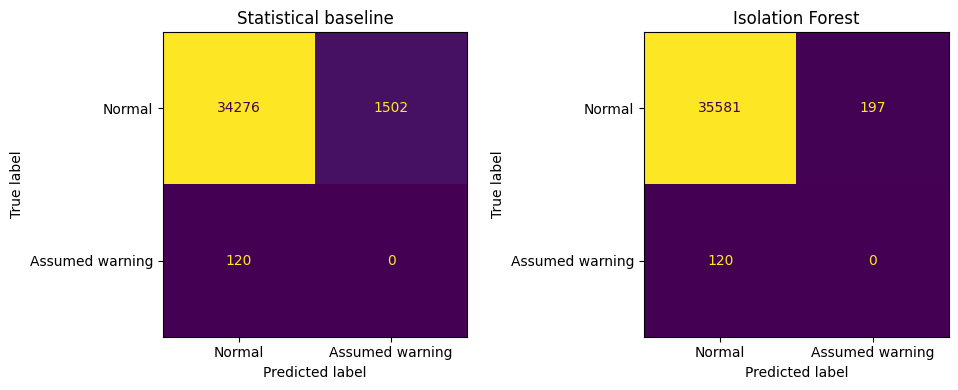

Incident-level check within the July test period:


,Incident,Incident start,Model,Assumed warning minutes,Warning minutes flagged,Warning recall,Any alert in assumed warning window
0,4,2020-07-15 14:30:00,Statistical baseline,120,0,0.0,False
1,4,2020-07-15 14:30:00,Isolation Forest,120,0,0.0,False


In [9]:
def make_predictions(frame, labels, baseline_scores, iso_scores):
    result = pd.DataFrame({
        "timestamp": frame["timestamp"].to_numpy(),
        "assumed_warning_label": np.asarray(labels, dtype=int),
        "baseline_score": np.asarray(baseline_scores, dtype=float),
        "isolation_forest_score": np.asarray(iso_scores, dtype=float),
    })
    result["baseline_alert"] = (result["baseline_score"] >= thresholds["Statistical baseline"]).astype(int)
    result["isolation_forest_alert"] = (result["isolation_forest_score"] >= thresholds["Isolation Forest"]).astype(int)
    for col in sensor_features:
        result[col] = frame[col].to_numpy()
    return result

validation_predictions = make_predictions(val_df, y_val, baseline_val_score, iso_val_score)
test_predictions = make_predictions(test_df, y_test, baseline_test_score, iso_test_score)

def evaluate(labels, baseline_scores, iso_scores):
    labels = np.asarray(labels, dtype=int)
    rows = []
    for name, scores in [
        ("Statistical baseline", baseline_scores),
        ("Isolation Forest", iso_scores),
    ]:
        scores = np.asarray(scores, dtype=float)
        predictions = (scores >= thresholds[name]).astype(int)
        fp = int(((predictions == 1) & (labels == 0)).sum())
        normal_count = max(int((labels == 0).sum()), 1)
        rows.append({
            "Model": name,
            "Threshold": thresholds[name],
            "Precision": precision_score(labels, predictions, zero_division=0),
            "Recall": recall_score(labels, predictions, zero_division=0),
            "F1-score": f1_score(labels, predictions, zero_division=0),
            "PR-AUC": average_precision_score(labels, scores) if len(np.unique(labels)) > 1 else float("nan"),
            "Warning prevalence": float(labels.mean()),
            "Alert minutes": int(predictions.sum()),
            "False-positive minutes": fp,
            "False positives per 1000 normal minutes": 1000 * fp / normal_count,
        })
    return pd.DataFrame(rows)

validation_metrics = evaluate(y_val, baseline_val_score, iso_val_score)
results_df = evaluate(y_test, baseline_test_score, iso_test_score)
print("June validation metrics:")
display(validation_metrics.round(4))
print("July held-out test metrics:")
display(results_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, alert_col) in zip(axes, [
    ("Statistical baseline", "baseline_alert"),
    ("Isolation Forest", "isolation_forest_alert"),
]):
    cm = confusion_matrix(y_test, test_predictions[alert_col], labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["Normal", "Assumed warning"]).plot(
        ax=ax, values_format="d", colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

event_rows = []
for incident_no, (start_text, end_text) in enumerate(failure_intervals, start=1):
    start = pd.Timestamp(start_text)
    event_data = test_predictions.loc[
        (test_predictions["timestamp"] >= start - warning_period)
        & (test_predictions["timestamp"] < start)
    ]
    if event_data.empty:
        continue
    for model_name, alert_col in [
        ("Statistical baseline", "baseline_alert"),
        ("Isolation Forest", "isolation_forest_alert"),
    ]:
        event_rows.append({
            "Incident": incident_no,
            "Incident start": start,
            "Model": model_name,
            "Assumed warning minutes": len(event_data),
            "Warning minutes flagged": int(((event_data["assumed_warning_label"] == 1) & (event_data[alert_col] == 1)).sum()),
            "Warning recall": recall_score(event_data["assumed_warning_label"], event_data[alert_col], zero_division=0),
            "Any alert in assumed warning window": bool(event_data[alert_col].any()),
        })
event_results = pd.DataFrame(event_rows)
print("Incident-level check within the July test period:")
display(event_results if not event_results.empty else pd.DataFrame({"Note": ["No documented incident warning window falls inside the test period."]}))

## 9. Save reproducible outputs

This creates a model bundle, validation/test predictions, comparison metrics, event-level results, metadata, and a ZIP for the report and dashboard.

In [10]:
OUTPUT_DIR = Path("/content/metroguard_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model_bundle = {
    "model_name": "Isolation Forest",
    "model": iso_model,
    "scaler": scaler,
    "feature_cols": feature_cols,
    "sensor_features": sensor_features,
    "threshold": float(thresholds["Isolation Forest"]),
    "baseline_mean": baseline_mean,
    "baseline_std": baseline_std,
    "baseline_threshold": float(thresholds["Statistical baseline"]),
    "warning_horizon_minutes": 120,
    "failure_intervals": failure_intervals,
}
joblib.dump(model_bundle, OUTPUT_DIR / "metroguard_model.joblib")
validation_metrics.to_csv(OUTPUT_DIR / "validation_metrics.csv", index=False)
results_df.to_csv(OUTPUT_DIR / "model_metrics.csv", index=False)
validation_predictions.to_csv(OUTPUT_DIR / "validation_predictions.csv", index=False)
test_predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
event_results.to_csv(OUTPUT_DIR / "event_evaluation.csv", index=False)

metadata = {
    "project": "MetroGuard: Metro train air-compressor anomaly monitoring",
    "dataset_source": "UCI Machine Learning Repository — MetroPT-3 Dataset (ID 791)",
    "dataset_url": "https://archive.ics.uci.edu/dataset/791/metropt3%2Bdataset",
    "dataset_start": str(df["timestamp"].min()),
    "dataset_end": str(df["timestamp"].max()),
    "raw_rows": int(len(df)),
    "minute_rows": int(len(minute_df)),
    "model_ready_rows": int(len(model_df)),
    "sensor_count": len(sensor_features),
    "feature_count": len(feature_cols),
    "train_period": "Before June 2020",
    "validation_period": "June 2020",
    "test_period": "July 2020",
    "threshold_rule": "Threshold selected on normal June validation scores to target approximately 1% false-positive rate; fixed for July test.",
    "thresholds": {k: float(v) for k, v in thresholds.items()},
    "warning_label_assumption": "The 120 minutes before each documented incident are treated as assumed warning minutes. The dataset does not provide verified labels for each minute.",
    "limitations": [
        "The two-hour warning window is an experimental assumption, not a verified target label.",
        "The July test period contains only one documented incident.",
        "An anomaly alert is not a calibrated probability of failure or a safety guarantee."
    ]
}
with open(OUTPUT_DIR / "project_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

zip_path = Path("/content/metroguard_outputs.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in OUTPUT_DIR.iterdir():
        if path.is_file():
            archive.write(path, arcname=path.name)
print("Saved outputs:", sorted(p.name for p in OUTPUT_DIR.iterdir() if p.is_file()))
print("ZIP:", zip_path)

Saved outputs: ['event_evaluation.csv', 'metroguard_model.joblib', 'model_metrics.csv', 'project_metadata.json', 'test_predictions.csv', 'validation_metrics.csv', 'validation_predictions.csv']
ZIP: /content/metroguard_outputs.zip


In [11]:
from google.colab import files
files.download(str(zip_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Build and launch the monitoring dashboard

The dashboard reads the saved evaluation files; it does not retrain the model. Run this section after the output ZIP has been created. Colab provides a temporary public tunnel URL while the runtime remains active.

In [12]:
%pip -q install streamlit plotly
from pathlib import Path
import shutil

DASHBOARD_DIR = Path("/content/MetroGuard_Dashboard")
ARTIFACT_DIR = DASHBOARD_DIR / "artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Copy the exact outputs created by this notebook into the dashboard's artifact folder.
for filename in [
    "model_metrics.csv", "validation_metrics.csv",
    "validation_predictions.csv", "test_predictions.csv",
    "event_evaluation.csv", "project_metadata.json",
    "metroguard_model.joblib",
]:
    shutil.copy2(OUTPUT_DIR / filename, ARTIFACT_DIR / filename)

print("Dashboard artifacts ready:", len(list(ARTIFACT_DIR.iterdir())))

Dashboard artifacts ready: 7


In [13]:
from pathlib import Path
APP_SOURCE = 'from pathlib import Path\nimport json\nimport zipfile\n\nimport numpy as np\nimport pandas as pd\nimport plotly.express as px\nimport plotly.graph_objects as go\nimport streamlit as st\n\nBASE_DIR = Path(__file__).resolve().parent\nARTIFACT_DIR = BASE_DIR / "artifacts"\n\nst.set_page_config(\n    page_title="MetroGuard | Compressor Monitoring",\n    page_icon="🚇",\n    layout="wide",\n)\n\nst.markdown("""\n<style>\n    .block-container {padding-top: 1.6rem; padding-bottom: 2.2rem; max-width: 1500px;}\n  [data-testid="stMetric"] {background: #202733 !important; color: #f4f7fb !important; padding: 14px 16px; border-radius: 10px; border: 1px solid #394354;} [data-testid="stMetricLabel"], [data-testid="stMetricLabel"] * {color: #cbd5e1 !important; opacity: 1 !important;} [data-testid="stMetricValue"], [data-testid="stMetricValue"] * {color: #ffffff !important; opacity: 1 !important;} \n    .small-note {font-size: 0.88rem; color: #536174;}\n    .status-warning {background:#fff5e8; color:#74400b; padding:12px 14px; border-radius:8px; border:1px solid #f5d7ad;}\n</style>\n""", unsafe_allow_html=True)\n\n\n@st.cache_data(show_spinner=False)\ndef load_csv(name):\n    return pd.read_csv(ARTIFACT_DIR / name, parse_dates=["timestamp"] if name.endswith("predictions.csv") else None)\n\n\ndef get_alert_episodes(df, alert_col="isolation_forest_alert"):\n    alerts = df.loc[df[alert_col].eq(1), ["timestamp", alert_col]].copy()\n    if alerts.empty:\n        return pd.DataFrame(columns=["Start", "End", "Minutes"])\n    alerts = alerts.sort_values("timestamp")\n    new_episode = alerts["timestamp"].diff().gt(pd.Timedelta(minutes=1))\n    alerts["episode"] = new_episode.cumsum()\n    episodes = alerts.groupby("episode").agg(\n        Start=("timestamp", "min"), End=("timestamp", "max"), Minutes=("timestamp", "size")\n    ).reset_index(drop=True)\n    return episodes.sort_values("Start", ascending=False)\n\n\nrequired = ["test_predictions.csv", "validation_predictions.csv", "model_metrics.csv", "validation_metrics.csv"]\nmissing = [name for name in required if not (ARTIFACT_DIR / name).exists()]\nif missing:\n    st.error("Project output files are missing: " + ", ".join(missing))\n    st.info("Extract the provided project package without changing the folder structure, then run the app again.")\n    st.stop()\n\ntest_df = load_csv("test_predictions.csv")\nval_df = load_csv("validation_predictions.csv")\ntest_metrics = load_csv("model_metrics.csv")\nval_metrics = load_csv("validation_metrics.csv")\n\nst.title("MetroGuard")\nst.caption("Metro train air-compressor condition monitoring · MetroPT-3 historical evaluation")\n\nst.markdown(\n    \'<div class="status-warning"><b>Evaluation note:</b> At the threshold selected using June validation data, \'\n    \'the saved July test results show no alerts during the assumed two-hour warning window for the reported incident. \'\n    \'This is an experimental anomaly-monitoring prototype, not a validated failure-prediction or safety system.</div>\',\n    unsafe_allow_html=True,\n)\n\nwith st.sidebar:\n    st.header("View settings")\n    period = st.radio("Evaluation period", ["July test", "June validation"], index=0)\n    active_df = test_df if period == "July test" else val_df\n    metrics_df = test_metrics if period == "July test" else val_metrics\n    st.divider()\n    st.write("**Data source**")\n    st.caption("UCI MetroPT-3 dataset. The dashboard displays saved outputs; it does not retrain the model.")\n\nmodel_row = metrics_df.loc[metrics_df["Model"].eq("Isolation Forest")]\nif model_row.empty:\n    st.error("Isolation Forest metrics were not found in the saved metrics file.")\n    st.stop()\nmodel_row = model_row.iloc[0]\nthreshold = float(model_row["Threshold"])\nalerts = active_df["isolation_forest_alert"].astype(int)\nlabels = active_df["assumed_warning_label"].astype(int)\nwarning_minutes = int(labels.sum())\ndetected_warning_minutes = int(((alerts == 1) & (labels == 1)).sum())\nfalse_alert_minutes = int(((alerts == 1) & (labels == 0)).sum())\n\nc1, c2, c3, c4, c5 = st.columns(5)\nc1.metric("Minutes analysed", f"{len(active_df):,}")\nc2.metric("ML alert minutes", f"{int(alerts.sum()):,}")\nc3.metric("Assumed warning minutes", f"{warning_minutes:,}")\nc4.metric("Warning minutes flagged", f"{detected_warning_minutes:,}")\nc5.metric("Alerts outside assumed warning window", f"{false_alert_minutes:,}")\n\nst.markdown("### Model evaluation")\nm1, m2, m3, m4 = st.columns(4)\nm1.metric("Precision", f"{float(model_row[\'Precision\']):.3f}")\nm2.metric("Recall", f"{float(model_row[\'Recall\']):.3f}")\nm3.metric("F1-score", f"{float(model_row[\'F1-score\']):.3f}")\nm4.metric("PR-AUC", f"{float(model_row[\'PR-AUC\']):.4f}")\nst.caption(f"Fixed threshold from validation: {threshold:.6f}. Warning labels are an assumed two-hour window before a reported incident, not verified labels for every minute.")\n\nsummary_tab, trend_tab, alerts_tab, comparison_tab = st.tabs(\n    ["Overview", "Sensor trends", "Alert timeline", "Model comparison"]\n)\n\nwith summary_tab:\n    left, right = st.columns([1.25, 1])\n    with left:\n        st.subheader("Anomaly score over time")\n        chart_df = active_df[["timestamp", "isolation_forest_score", "assumed_warning_label", "isolation_forest_alert"]].copy()\n        if len(chart_df) > 12000:\n            chart_df = chart_df.iloc[::5].copy()\n        fig = go.Figure()\n        fig.add_trace(go.Scatter(x=chart_df["timestamp"], y=chart_df["isolation_forest_score"], mode="lines", name="Anomaly score", line=dict(width=1.4, color="#2878b5")))\n        fig.add_hline(y=threshold, line_dash="dash", line_color="#cc6b31", annotation_text="Validation threshold")\n        flagged = chart_df[chart_df["isolation_forest_alert"].eq(1)]\n        if not flagged.empty:\n            fig.add_trace(go.Scatter(x=flagged["timestamp"], y=flagged["isolation_forest_score"], mode="markers", name="ML alert", marker=dict(color="#cc6b31", size=5)))\n        warn = chart_df[chart_df["assumed_warning_label"].eq(1)]\n        if not warn.empty:\n            fig.add_trace(go.Scatter(x=warn["timestamp"], y=warn["isolation_forest_score"], mode="markers", name="Assumed warning window", marker=dict(color="#8b3fa8", size=5, symbol="x")))\n        fig.update_layout(height=420, margin=dict(l=10, r=10, t=30, b=10), legend=dict(orientation="h", yanchor="bottom", y=1.02), xaxis_title="Time", yaxis_title="Score")\n        st.plotly_chart(fig, use_container_width=True)\n    with right:\n        st.subheader("Baseline vs ML")\n        comp = metrics_df[["Model", "Precision", "Recall", "F1-score", "PR-AUC", "False positives per 1000 normal minutes"]].copy()\n        st.dataframe(comp.round(4), use_container_width=True, hide_index=True)\n        st.markdown("**How to read this**")\n        st.write("The threshold is fixed from validation data. July is treated as held-out test data and is not used to tune the threshold.")\n        st.write("A flagged minute means the sensor pattern crossed the anomaly threshold. It does not prove that a compressor failure occurred.")\n\nwith trend_tab:\n    st.subheader("Sensor signals")\n    sensor_cols = [c for c in ["TP2", "TP3", "H1", "DV_pressure", "Reservoirs", "Oil_temperature", "Motor_current"] if c in active_df.columns]\n    selected = st.selectbox("Sensor", sensor_cols, index=sensor_cols.index("Oil_temperature") if "Oil_temperature" in sensor_cols else 0)\n    date_min = active_df["timestamp"].min().date()\n    date_max = active_df["timestamp"].max().date()\n    date_range = st.date_input("Time range", value=(date_min, date_max), min_value=date_min, max_value=date_max)\n    if isinstance(date_range, tuple) and len(date_range) == 2:\n        start_date, end_date = date_range\n    else:\n        start_date, end_date = date_min, date_max\n    view = active_df.loc[\n        active_df["timestamp"].between(pd.Timestamp(start_date), pd.Timestamp(end_date) + pd.Timedelta(days=1) - pd.Timedelta(seconds=1))\n    ].copy()\n    if len(view) > 15000:\n        view = view.iloc[::max(1, len(view)//15000)].copy()\n    fig = px.line(view, x="timestamp", y=selected, title=f"{selected} over time")\n    fig.update_traces(line_width=1.4, line_color="#2878b5")\n    fig.update_layout(height=430, margin=dict(l=10, r=10, t=50, b=10), xaxis_title="Time", yaxis_title=selected)\n    st.plotly_chart(fig, use_container_width=True)\n    if "isolation_forest_alert" in view:\n        flagged = view[view["isolation_forest_alert"].eq(1)]\n        if not flagged.empty:\n            st.caption(f"Orange alert markers are summarized in the Alert timeline tab. {len(flagged):,} alert minutes fall in this time range.")\n\nwith alerts_tab:\n    st.subheader("Alert episodes")\n    episodes = get_alert_episodes(active_df)\n    if episodes.empty:\n        st.info("No Isolation Forest alert minutes were saved for this period at the selected threshold.")\n    else:\n        st.write(f"Consecutive alert minutes are grouped into episodes. {len(episodes):,} episodes were found.")\n        st.dataframe(episodes.head(100).style.format({"Minutes": "{:,.0f}"}), use_container_width=True, hide_index=True)\n        st.download_button("Download alert episodes (CSV)", episodes.to_csv(index=False).encode("utf-8"), file_name=f"{period.lower().replace(\' \', \'_\')}_alert_episodes.csv", mime="text/csv")\n    st.subheader("Assumed warning-window check")\n    st.write(f"Assumed warning minutes flagged by the model: **{detected_warning_minutes:,} / {warning_minutes:,}**.")\n    if warning_minutes and detected_warning_minutes == 0:\n        st.warning("No assumed warning minutes were flagged at this fixed threshold. Do not describe this run as successful early-failure prediction.")\n\nwith comparison_tab:\n    st.subheader("Statistical baseline and Isolation Forest")\n    compare = metrics_df.set_index("Model")[["Precision", "Recall", "F1-score", "PR-AUC", "False positives per 1000 normal minutes"]]\n    st.dataframe(compare.round(4), use_container_width=True)\n    fig = px.bar(metrics_df, x="Model", y="PR-AUC", title="Precision–recall average precision", text_auto=".4f")\n    fig.update_layout(height=360, margin=dict(l=10, r=10, t=50, b=10), yaxis_title="Average precision")\n    st.plotly_chart(fig, use_container_width=True)\n    st.markdown("**Important limitation:** The dataset provides four reported incident periods, not verified labels for every timestamp. The two-hour warning windows are a project assumption; the July test period contains one incident, so the result does not establish general failure-prediction performance.")\n\nst.divider()\nst.caption("MetroGuard · AUCML ESE prototype · Historical sensor analysis only; not a live railway monitoring or safety system.")\n'
app_path = Path('/content/MetroGuard_Dashboard/app.py')
app_path.write_text(APP_SOURCE, encoding='utf-8')
print('Dashboard app saved:', app_path)

Dashboard app saved: /content/MetroGuard_Dashboard/app.py


In [14]:
# Start Streamlit and the temporary Cloudflare tunnel.
import subprocess, sys, time, re, urllib.request
from pathlib import Path

log_path = Path("/content/metroguard_streamlit.log")
with open(log_path, "w") as log:
    streamlit_proc = subprocess.Popen(
        [sys.executable, "-m", "streamlit", "run", "/content/MetroGuard_Dashboard/app.py",
         "--server.address", "127.0.0.1", "--server.port", "8501",
         "--server.headless", "true"],
        stdout=log, stderr=subprocess.STDOUT, start_new_session=True
    )

# Confirm the local dashboard responds before opening the tunnel.
healthy = False
for _ in range(30):
    time.sleep(2)
    try:
        urllib.request.urlopen("http://127.0.0.1:8501/_stcore/health", timeout=2)
        healthy = True
        break
    except Exception:
        pass

if not healthy:
    print(log_path.read_text(errors="ignore")[-4000:])
    raise RuntimeError("Streamlit did not start. Review the log above.")

cloudflared_path = Path("/content/cloudflared")
if not cloudflared_path.exists():
    subprocess.run(
        ["bash", "-lc", "wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared && chmod +x /content/cloudflared"],
        check=True
    )

tunnel_log = open("/content/metroguard_tunnel.log", "w")
tunnel_proc = subprocess.Popen(
    [str(cloudflared_path), "tunnel", "--url", "http://127.0.0.1:8501"],
    stdout=tunnel_log, stderr=subprocess.STDOUT, start_new_session=True
)

dashboard_url = None
for _ in range(30):
    time.sleep(2)
    try:
        tunnel_text = Path("/content/metroguard_tunnel.log").read_text(errors="ignore")
        match = re.search(r"https://[a-zA-Z0-9-]+\.trycloudflare\.com", tunnel_text)
        if match:
            dashboard_url = match.group(0)
            break
    except Exception:
        pass

if dashboard_url:
    print("MetroGuard dashboard is ready:")
    print(dashboard_url)
    print("Keep this Colab runtime running while using the dashboard.")
else:
    print("Streamlit is running locally, but the temporary tunnel URL was not detected.")
    print(Path("/content/metroguard_tunnel.log").read_text(errors="ignore")[-3000:])

MetroGuard dashboard is ready:
https://kate-game-gateway-tasks.trycloudflare.com
Keep this Colab runtime running while using the dashboard.
